In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")

print("Dataset shape:", df.shape)

Dataset shape: (284807, 31)


In [3]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (227845, 30)
X_test: (56962, 30)


In [5]:
X_train = X_train.copy()
X_test = X_test.copy()

# -------------------------
# Time features
# -------------------------

X_train["TransactionHour"] = (
    (X_train["Time"] // 3600) % 24
)

X_test["TransactionHour"] = (
    (X_test["Time"] // 3600) % 24
)

# -------------------------
# Cyclical encoding
# -------------------------

X_train["HourSin"] = np.sin(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_train["HourCos"] = np.cos(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_test["HourSin"] = np.sin(
    2 * np.pi * X_test["TransactionHour"] / 24
)

X_test["HourCos"] = np.cos(
    2 * np.pi * X_test["TransactionHour"] / 24
)

# -------------------------
# Amount transformation
# -------------------------

X_train["AmountLog"] = np.log1p(X_train["Amount"])
X_test["AmountLog"] = np.log1p(X_test["Amount"])

# -------------------------
# Amount bucket
# -------------------------

bins = [-1, 10, 50, 100, 500, 1000, np.inf]

X_train["AmountBucket"] = pd.cut(
    X_train["Amount"],
    bins=bins,
    labels=False
)

X_test["AmountBucket"] = pd.cut(
    X_test["Amount"],
    bins=bins,
    labels=False
)

print("Feature engineering completed.")
print("Training features:", X_train.shape[1])

Feature engineering completed.
Training features: 35


In [6]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("scale_pos_weight:", scale_pos_weight)

Negative samples: 227451
Positive samples: 394
scale_pos_weight: 577.2868020304569


In [7]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

In [8]:
xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed!")

XGBoost training completed!


In [9]:
y_pred = xgb_model.predict(X_test)

y_prob = xgb_model.predict_proba(X_test)[:, 1]

In [10]:
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.61      0.87      0.72        98

    accuracy                           1.00     56962
   macro avg       0.81      0.93      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [11]:
print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

print("PR-AUC:",
      average_precision_score(y_test, y_prob))

ROC-AUC: 0.9816354703811744
PR-AUC: 0.8528671148743486


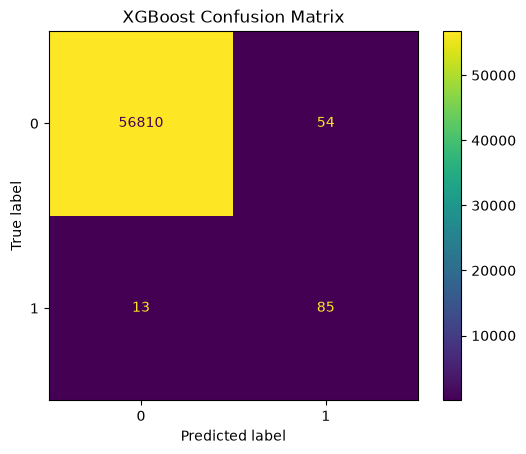

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [13]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
)

importance = importance.sort_values(
    ascending=False
)

print(importance.head(15))

V14                0.356525
V4                 0.056366
AmountLog          0.042276
V10                0.042085
V20                0.032053
V12                0.031900
Amount             0.030986
V8                 0.026414
V26                0.021525
V19                0.021492
TransactionHour    0.020457
V13                0.020446
V17                0.019290
V7                 0.018066
V21                0.016444
dtype: float32


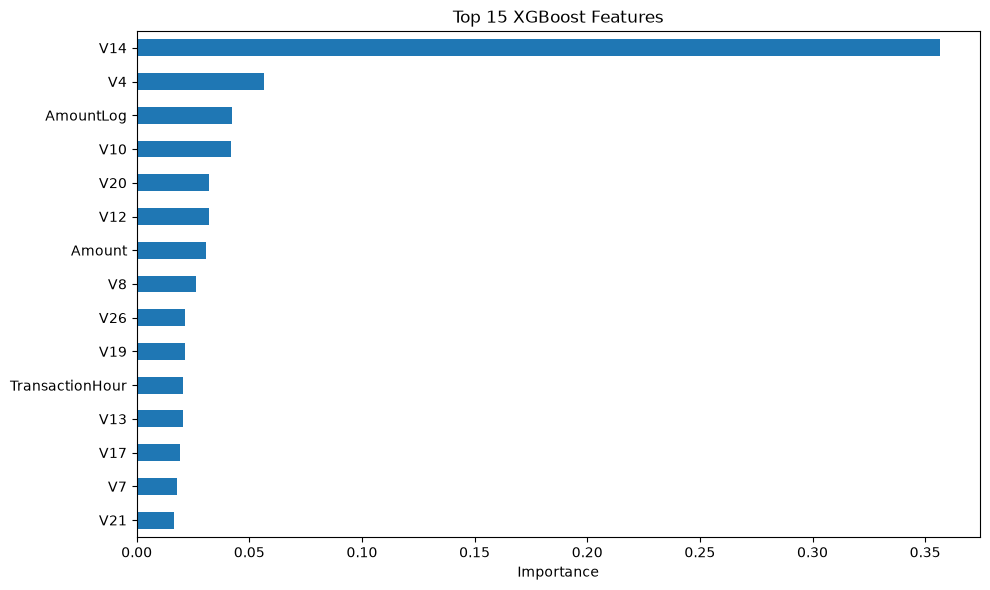

In [14]:
plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 XGBoost Features")
plt.xlabel("Importance")

plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import RandomizedSearchCV

In [16]:
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

In [17]:
xgb_tuning_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

In [18]:
random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=param_grid,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [19]:
random_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 200, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a

In [20]:
print("Best parameters:")
print(random_search.best_params_)

Best parameters:
{'subsample': 0.7, 'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [21]:
print("Best parameters:")
print(random_search.best_params_)

Best parameters:
{'subsample': 0.7, 'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [22]:
best_xgb = random_search.best_estimator_

In [23]:
y_pred_best = best_xgb.predict(X_test)

y_prob_best = best_xgb.predict_proba(X_test)[:, 1]

In [24]:
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_best))

print("PR-AUC:",
      average_precision_score(y_test, y_prob_best))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.89      0.83      0.86        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9835584258323476
PR-AUC: 0.8835440899195941


In [25]:
comparison = pd.DataFrame([
    {
        "Model": "Tuned XGBoost",
        "Precision": precision_score(
            y_test,
            y_pred_best,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred_best,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            y_pred_best,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_prob_best
        ),
        "PR-AUC": average_precision_score(
            y_test,
            y_prob_best
        )
    }
])

comparison

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Tuned XGBoost,0.89011,0.826531,0.857143,0.983558,0.883544
